<a href="https://colab.research.google.com/github/nahulanr05-jpg/credicare/blob/main/First_test_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
print("hello world")

hello world


### How to Install Python Libraries in Colab

You can install any Python library using `!pip install <package_name>`. The `!` tells Colab to execute the line as a shell command rather than Python code.

*Note: Many popular libraries like `numpy`, `pandas`, `matplotlib`, and `scikit-learn` are pre-installed by default.*

In [7]:
# Example: Installing the 'requests' library (even though it's already pre-installed)
!pip install requests

### Step-by-Step Machine Learning Template

This template demonstrates a standard supervised learning workflow (Classification) using `scikit-learn`. You can replace the dataset loading part with your own local CSV file, Google Drive file, or public URL.

In [8]:
# Step 1: Import libraries and load dataset
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.datasets import load_iris

# For this demonstration, we use the Iris flower dataset
# To use your own CSV file, you could run:
# df = pd.read_csv('path_to_your_dataset.csv')

iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [9]:
# Step 2: Separate features (X) and target variable (y), then split into Train/Test sets
X = df.drop(columns=['target'])
y = df['target']

# Split: 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 120 samples
Testing set size: 30 samples


In [10]:
# Step 3: Train the Machine Learning model
# We will use a RandomForest Classifier, which is a great baseline model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
print("Model training completed successfully!")

Model training completed successfully!


In [11]:
# Step 4: Make predictions and evaluate performance
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f} (or {accuracy * 100:.1f}%)\n")

print("Detailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 1.00 (or 100.0%)

Detailed Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



### Exploring a New Domain: California Housing Price Prediction (Regression)

We will use the California Housing dataset which is already pre-loaded in your Colab files under `sample_data/`. Our target variable will be `median_house_value`.

In [12]:
# Load the built-in California Housing training dataset
import pandas as pd

housing_df = pd.read_csv('/content/sample_data/california_housing_train.csv')

# Let's see what features are available for our model
print("Dataset Dimensions:", housing_df.shape)
display(housing_df.head())

Dataset Dimensions: (17000, 9)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


### Preparing the Data and Training the Regressor

We will define our target variable `y` as `median_house_value` and use the rest of the columns as features `X`. Then we will train a `LinearRegression` model.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Define Features and Target
X_house = housing_df.drop(columns=['median_house_value'])
y_house = housing_df['median_house_value']

# 2. Split into training and testing sets (80% train, 20% test)
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(X_house, y_house, test_size=0.2, random_state=42)

# 3. Initialize and train the Linear Regression Model
regressor = LinearRegression()
regressor.fit(X_train_h, y_train_h)

# 4. Predict and Evaluate
y_pred_h = regressor.predict(X_test_h)

mae = mean_absolute_error(y_test_h, y_pred_h)
r2 = r2_score(y_test_h, y_pred_h)

print(f"Mean Absolute Error: ${mae:,.2f}")
print(f"R-squared Score: {r2:.4f}")

Mean Absolute Error: $49,983.47
R-squared Score: 0.6636


### Upgrading the Model to Random Forest Regressor

Now, let's use a non-linear ensemble model (`RandomForestRegressor`) to see if we can reduce the error and increase our R-squared score.

In [14]:
from sklearn.ensemble import RandomForestRegressor

# 1. Initialize the Random Forest Regressor
rf_regressor = RandomForestRegressor(n_estimators=100, random_state=42)

# 2. Train the model
rf_regressor.fit(X_train_h, y_train_h)

# 3. Predict and Evaluate
y_pred_rf = rf_regressor.predict(X_test_h)

mae_rf = mean_absolute_error(y_test_h, y_pred_rf)
r2_rf = r2_score(y_test_h, y_pred_rf)

print(f"Random Forest - Mean Absolute Error: ${mae_rf:,.2f}")
print(f"Random Forest - R-squared Score: {r2_rf:.4f}")

Random Forest - Mean Absolute Error: $32,359.79
Random Forest - R-squared Score: 0.8228


### Visualizing Model Performance Comparison

Let's plot the actual values against the predicted values for both Linear Regression and Random Forest. In a perfect prediction scenario, all points would lie on the diagonal line ($y = x$).

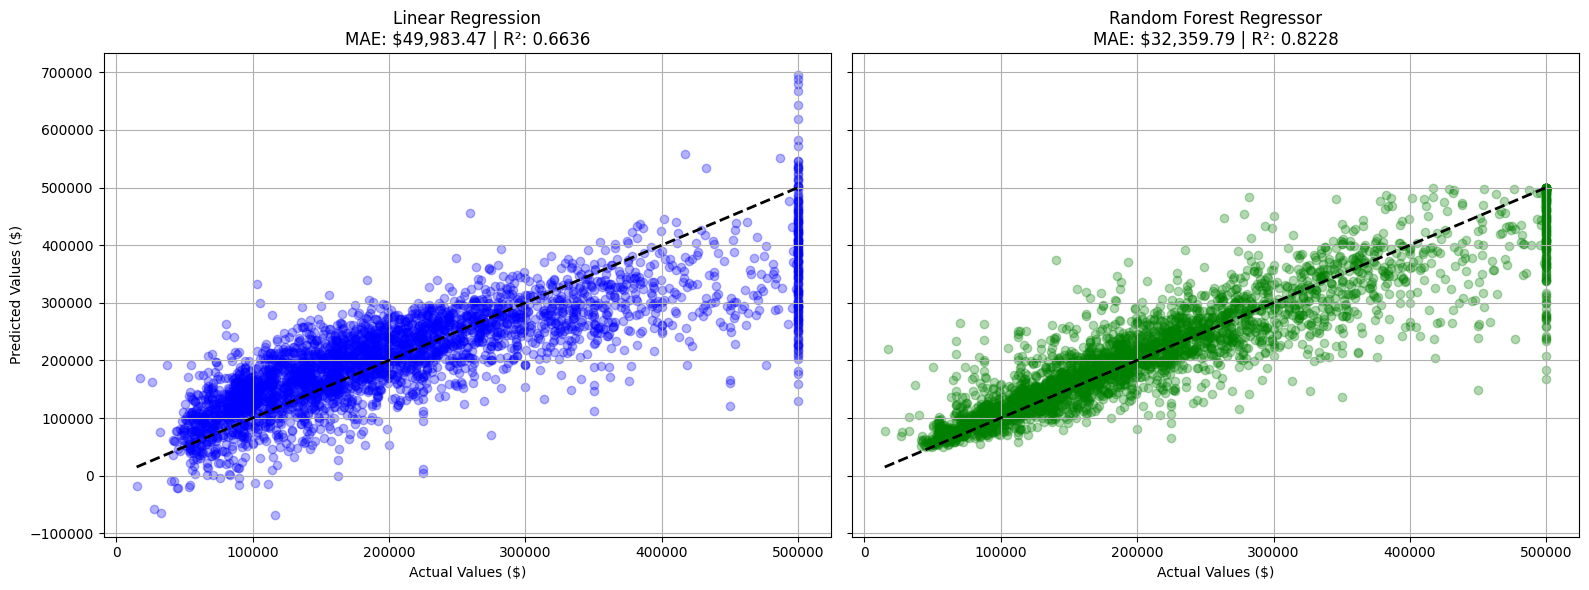

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Set up the plotting area with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Plot Linear Regression Predictions
axes[0].scatter(y_test_h, y_pred_h, alpha=0.3, color='blue')
axes[0].plot([y_test_h.min(), y_test_h.max()], [y_test_h.min(), y_test_h.max()], 'k--', lw=2)
axes[0].set_title(f'Linear Regression\nMAE: ${mae:,.2f} | R²: {r2:.4f}')
axes[0].set_xlabel('Actual Values ($)')
axes[0].set_ylabel('Predicted Values ($)')
axes[0].grid(True)

# Plot Random Forest Predictions
axes[1].scatter(y_test_h, y_pred_rf, alpha=0.3, color='green')
axes[1].plot([y_test_h.min(), y_test_h.max()], [y_test_h.min(), y_test_h.max()], 'k--', lw=2)
axes[1].set_title(f'Random Forest Regressor\nMAE: ${mae_rf:,.2f} | R²: {r2_rf:.4f}')
axes[1].set_xlabel('Actual Values ($)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Upgrading to Deep Learning (A Neural Network)

To move closer to 'models that learn by themselves,' we can build a Basic Neural Network using TensorFlow/Keras. A neural network learns representations from the raw features by passing them through layers of interconnected 'neurons' that automatically adjust through backpropagation.

In [16]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.preprocessing import StandardScaler

# Neural Networks perform significantly better when inputs are scaled
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_h)
X_test_scaled = scaler.transform(X_test_h)

# Build the neural network architecture
keras_model = models.Sequential([
    layers.Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)  # Output layer for regression
])

# Compile the model with an optimizer that dynamically adjusts learning rate
keras_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Train the neural network
print("Training the Neural Network...")
history = keras_model.fit(
    X_train_scaled, y_train_h,
    validation_split=0.1,
    epochs=40,
    batch_size=32,
    verbose=1
)

# Evaluate neural network prediction
y_pred_nn = keras_model.predict(X_test_scaled).flatten()
mae_nn = mean_absolute_error(y_test_h, y_pred_nn)
r2_nn = r2_score(y_test_h, y_pred_nn)

print(f"\nNeural Network - Mean Absolute Error: ${mae_nn:,.2f}")
print(f"Neural Network - R-squared Score: {r2_nn:.4f}")

Training the Neural Network...
Epoch 1/40


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


383/383 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 51858153472.0000 - mae: 196630.7500 - val_loss: 36095668224.0000 - val_mae: 156441.1562
Epoch 2/40
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 16794499072.0000 - mae: 95969.7891 - val_loss: 12184427520.0000 - val_mae: 77092.0781
Epoch 3/40
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 9360290816.0000 - mae: 69927.0391 - val_loss: 9538336768.0000 - val_mae: 68305.0703
Epoch 4/40
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 7626801664.0000 - mae: 62851.9648 - val_loss: 7945835008.0000 - val_mae: 63197.9805
Epoch 5/40
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 6574785536.0000 - mae: 58653.3438 - val_loss: 6883567616.0000 - val_mae: 59167.7539
Epoch 6/40
383/383 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 5833075712.0000 - mae: 55361.9258 - val_loss: 6136947200.0000 - val_mae: 56279.5195
Epoch 7/40
383/383 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 5323500544.0000 - mae: 53026.9062 - val_loss: 5657070080.0000 - val_mae: 54509.20